# Airfoil Simple Kriging

Load the NACA airfoil coordinates and predict. The coordinates should be arranged in one sense. Meaning, that `XB` and `YB` are either in a clockwise or anti-clockwise arrangement. 

## Exact solution

The true velocity is computed using the BEM code. 
GRID discretization used:    

```{python}
# Grid parameters
nGridX   = 30                                                             # X-grid for streamlines and contours
nGridY   = 30                                                             # Y-grid for streamlines and contours
xVals    = [min(XB)-0.5, max(XB)+0.5]                                     # X-grid extents [min, max]
yVals    = [min(YB)-0.2, max(YB)+0.2]                                     # Y-grid extents [min, max]
```

In [1]:
# imports 
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import Polygon, Point
# from scipy.interpolate import griddata
from matrices import CovM, CovFn 
from covderivatives2D import AnalyticalSqExpdiff2D
from calibration import LOOMSESK2D, LOOVARSK2D, adamopt, Adam
import matplotlib.cm as cm
from matplotlib.colors import Normalize

Importing covderivatives.py
Importing covderivatives2D.py


In [2]:
# Image path to save the images.
IMGPATH = r'IMAGES/' 

# load the NACA airfoil data
NACAname = r'0012'
XB, YB, nX, nY = np.loadtxt('data/NACA'+NACAname+'UIUCnormalvecs.dat', 
                            unpack=True)
XX, YY, Vx, Vy = np.loadtxt('data/NACA'+NACAname+'BEMflow.dat',
                            unpack=True)

## Defining relevant points in the extended design space.
 - Observation points (`Obs`). $v_x \rightarrow$ `m = (1,0)`. $v_y \rightarrow$ `m = (0,1)`.
 - Prediction points (`Pred`). `m = (1,0)` \& `m = (0,1)`.

In [3]:
# USER INPUTS
## Observation locations with derivative orders.
nobs = 20                                  # number of observations (at inf. on each side)
nm = 20                                    # number of observations in the middle of the domain.
UQFLAG = 1                                 # For uncertainty prediction
ostep = int(np.sqrt(XX.shape[0])/nobs)     # step size to select observation points at infinity.
mstep = int(np.sqrt(XX.shape[0])/nm)       # step size to select observation points in the domain.

In [4]:
# Observation locations
mask = np.zeros_like(XX, dtype = bool)      # mask to choose the right observation indices.

for _ in np.where(XX==min(XX))[0][::ostep]:
    mask[_] = True;                         # observations at -infinity.
for _ in np.where(XX==max(XX))[0][::ostep]:
    mask[_] = True;                         # observations at +infinity.
for _ in np.where(YY==min(YY))[0][mstep::mstep]:
    mask[_] = True;                         # (upper) mid-domain observations (avoiding redundancy)
for _ in np.where(YY==max(YY))[0][mstep::mstep]:
    mask[_] = True;                         # (lower) mid-domain observations (avoiding redundancy)

nobs = np.sum(mask)                         # redefining nobs based on the chosen locations.
Obs = np.zeros((2*nobs, 2, 2))              # Observations of [Vx, Vy].

## Setting the appropriate locations. 
Obs[:nobs, 0, 0] = XX[mask]; 
Obs[:nobs, 0, 1] = YY[mask] 
Obs[nobs:, 0, :] = Obs[:nobs, 0, :]         # repeating the same observation locations.

## Setting the right order of derivatives. 
Obs[:nobs, 1, 0] = 1; Obs[nobs:, 1, 1] = 1  # m = (1,0) and m = (0,1) 

In [5]:
# TEST : Is the `mask` vector properly defined?
# plt.scatter(XX[mask], YY[mask], marker = 'x')
# plt.quiver(XX[mask], YY[mask],
#            Vx[mask], Vy[mask])
# plt.show() 

In [6]:
# prediction points
q = XX.shape[0]                      # NUM prediction points.
Pred = np.zeros((2*q, 2, 2))         # initialize the prediction locations. 

# Airfoil shape definition.
airfoilshape = Polygon(np.column_stack([XB, YB]))   # Defining a polygon based on the airfoil profile.
airfoilcontains = lambda x, y: airfoilshape.contains(Point(x, y))   # Function to check if point is within airfoil. 

# Setting the right locations.
Pred[:q, 0, :] = np.column_stack([XX, YY])
Pred[q:, 0, :] = Pred[:q, 0, :]

# Setting the right order of derivatives. 
Pred[:q, 1, 0] = 1                        # m = (1,0)
Pred[q:, 1, 1] = 1                        # m = (0,1)

# creating a mask to set predictions inside the airfoil to zero.
withinairfoil = np.array(list(map(airfoilcontains, 
                                    XX, 
                                    YY)))

In [7]:
# TEST : Are the prediction locations correct? 
# plt.scatter(Pred[:q, 0, 0][~withinairfoil], 
#             Pred[q:, 0, 1][~withinairfoil], marker = 'x')
# plt.plot(XB, YB)
# plt.show()

## Kernel hyperparameters and covariance matrices
Set the variables `sigma` and `theta` to construct the covariance matrices OR opt for LOOCV hyperparameter tuning by setting `hypropt=1`.

In [8]:
# USER INPUTS
hypropt = 1;                                    # Flag to perform LOOCV hyperparameter tuning
sigma = 1.0;                                    # Default noise variance
theta = 1.0;                                    # Default lengthscale / correlation parameter.  

# Exact observations
n = Obs.shape[0]                                # True velocity observations.
ytrue = np.zeros(n)                             # Full vector of observations.
ytrue[:int(n/2)] = Vx[mask];                    # vx obs first and then vy obs.
ytrue[int(n/2):n] = Vy[mask];

# Matrix K
def Kmatfn(params):
    CovParam = lambda *Z: CovM(*Z, kernel=AnalyticalSqExpdiff2D, **params)
    K = CovParam(Obs);
    return K

Iter 1/100 - LOOMSE: 0.000   lengthscale: 0.259
Iter 2/100 - LOOMSE: 0.000   lengthscale: 0.269
Iter 3/100 - LOOMSE: 0.000   lengthscale: 0.267
Iter 4/100 - LOOMSE: 0.000   lengthscale: 0.260
Iter 5/100 - LOOMSE: 0.000   lengthscale: 0.253
Iter 6/100 - LOOMSE: 0.000   lengthscale: 0.251
Iter 7/100 - LOOMSE: 0.000   lengthscale: 0.252
Iter 8/100 - LOOMSE: 0.000   lengthscale: 0.256
Iter 9/100 - LOOMSE: 0.000   lengthscale: 0.258
Iter 10/100 - LOOMSE: 0.000   lengthscale: 0.260
Iter 11/100 - LOOMSE: 0.000   lengthscale: 0.265
Iter 12/100 - LOOMSE: 0.000   lengthscale: 0.271
Iter 13/100 - LOOMSE: 0.000   lengthscale: 0.277
Iter 14/100 - LOOMSE: 0.000   lengthscale: 0.282
Iter 15/100 - LOOMSE: 0.000   lengthscale: 0.289
Iter 16/100 - LOOMSE: 0.000   lengthscale: 0.295
Iter 17/100 - LOOMSE: 0.000   lengthscale: 0.300
Iter 18/100 - LOOMSE: 0.000   lengthscale: 0.305
Iter 19/100 - LOOMSE: 0.000   lengthscale: 0.308
Iter 20/100 - LOOMSE: 0.000   lengthscale: 0.311
Iter 21/100 - LOOMSE: 0.000  

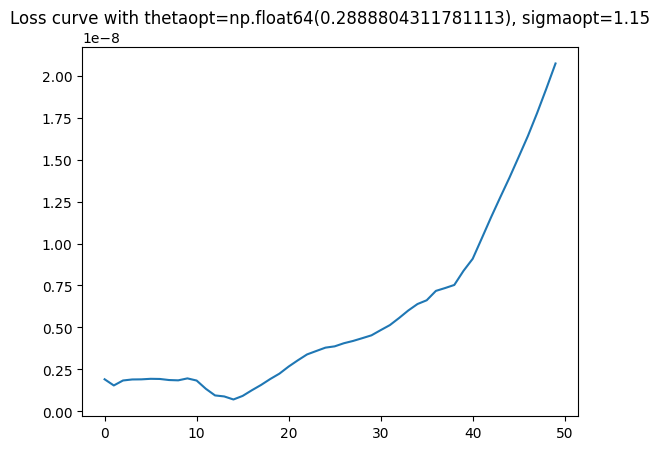

In [9]:
##########################
# LOOCV optimization step
##########################
if hypropt == 1:
    bL = 0.2; bR = 0.3                                  # left and right bounds
    bounds = [bL, bR]                                   # To initialize theta (correlation parameter)
    n_iter = 100
    loomsefn = lambda theta: LOOMSESK2D(theta, ytrue, Kmatfn, sigma = 1.0)
    thetaopt, optscore, history = adamopt(loomsefn, bounds, n_iter = n_iter, stoploss = 50)
    print(f'{thetaopt=}'); print(f'{optscore=:.4f}')
    sigmaopt = LOOVARSK2D(ytrue, Kmatfn, dict(theta = thetaopt,
                                                sigma = 1.0), nugget = 1e-10)
    print(f'{sigmaopt=:.2f}')
    plt.figure()
    if not np.sum(history==1e10) == 0:                  # To check IF the stopping criterion was invoked
        stopindex = int(np.where(history==1e10)[0][0])  # WHERE the stopping criteria was invoked
        plt.plot(range(stopindex - 1), history[:stopindex-1]); plt.title(f'Loss curve with {thetaopt=}, {sigmaopt=:.2f}')
    else: 
        plt.plot(range(n_iter), history); plt.title(f'Loss curve with {thetaopt=}, {sigmaopt=:.2f}')
    # plt.savefig(IMGPATH + 'lossAirfoilCK.pdf')
    # plt.show()      # To visualize LOOCV loss curve
else: 
    print(f'Using the fixed kernel params (user inputs): {theta=}, {sigma=:.2f}')
    thetaopt = theta; sigmaopt = sigma

## Matrix K (optimal)
K = Kmatfn(dict(theta = thetaopt,                       # LOOCV Optimal Kplus matrix 
                     sigma = 1.0)) 


## Final predictions and UQ

In [10]:
## Matrix H
params = dict(theta = thetaopt, sigma = 1.0)
CovParam = lambda *Zvals: CovM(*Zvals, kernel = AnalyticalSqExpdiff2D, **params)
PredOut = np.vstack([Pred[:q][~withinairfoil],              # vx outside airfoil
                     Pred[q:][~withinairfoil]])             # vy outside airfoil
H = CovParam(Obs, PredOut)

In [11]:
# Simple Kriging [yhat]
# yhat = np.zeros(2*q)                                       # Prediction of [Vx, Vy]
qout = int(PredOut.shape[0]/2)
nugget = 1e-10                                               # small nugget for numerical stability.
I = np.eye(K.shape[0]); nI = nugget * I
Kinv = np.linalg.solve(K + nI, I)
vxhat, vyhat = (H.T @ Kinv @ ytrue).reshape(2, qout)
# yhat = Hplus.T @ Kplusinv @ ytrue

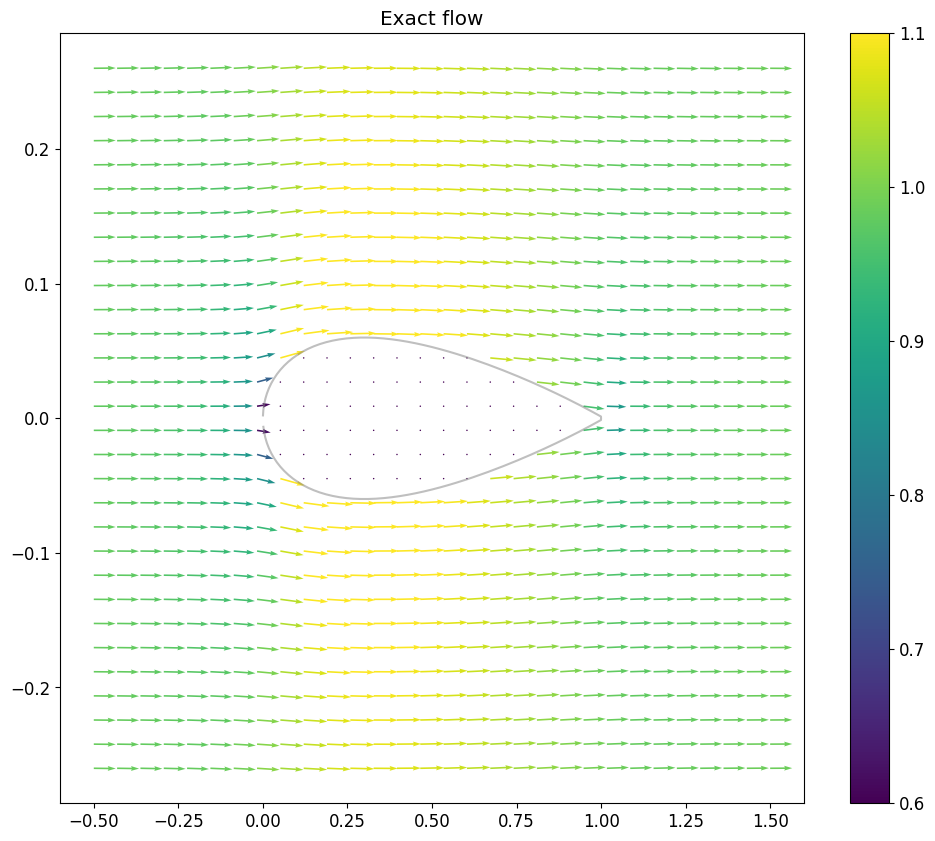

In [12]:
## Visualization true flow
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 12})    
widf = 1.5
plt.figure(figsize = (12, 10))
plt.cla()
quiverkwargs = dict(pivot = 'tail',
                    scale = 1/0.030, 
                    width = 3.25/(widf*1e3), 
                    clim = (0.6, 1.1))                                  # Colorbar
Q1 = plt.quiver(XX, YY,
                Vx, Vy,
                np.hypot(Vx, Vy), 
                alpha = 1,
                **quiverkwargs) 
plt.colorbar()
plt.plot(XB, YB,
         alpha = 0.5, c = 'grey', label='Obstacle')
plt.title(f'Exact flow')
# plt.xlim(-1,2)
# plt.ylim(-1.4, 1.4)
# if figsave == 1:
#     plt.savefig(IMGPATH+'AirfoilCK.pdf', dpi = 300, bbox_inches = 'tight', pad_inches = 0)
plt.show()




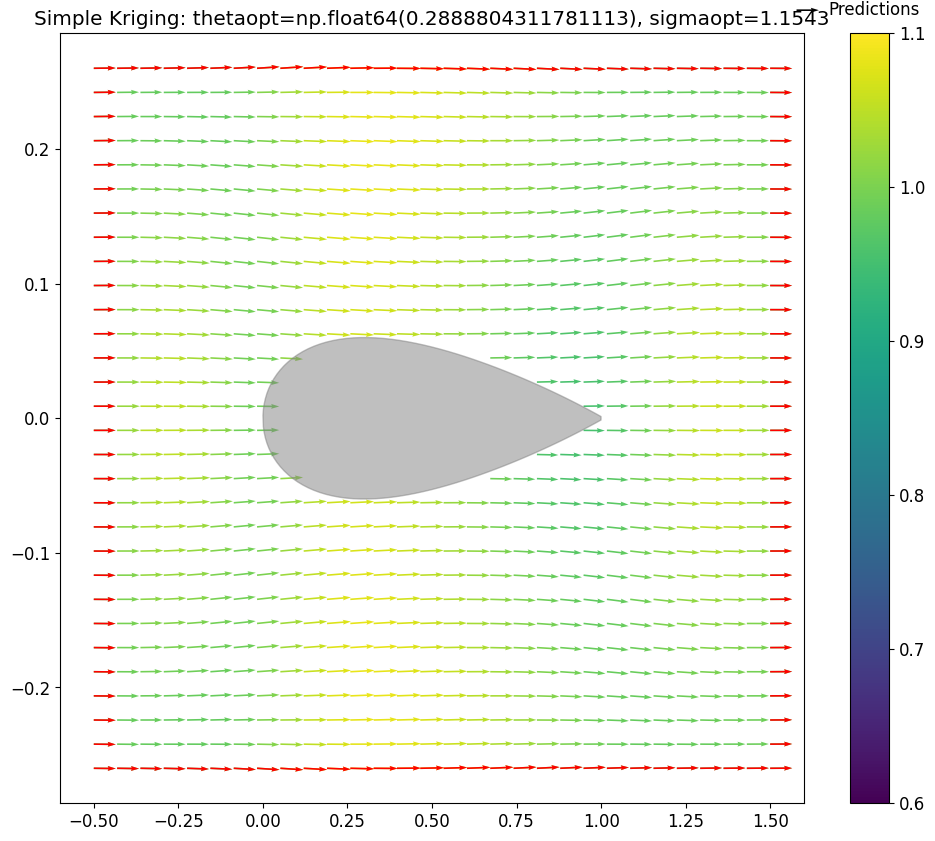

In [13]:
## Visualization Co-Kriging flow prediction
plt.figure(figsize = (12, 10))
plt.cla()
Q2 = plt.quiver(PredOut[:qout, 0, 0], PredOut[:qout, 0, 1],
                vxhat, vyhat,
                np.hypot(vxhat, vyhat), 
                alpha = 1.0,
                **quiverkwargs)
plt.colorbar()
Q1 = plt.quiver(XX[mask], YY[mask],
                Vx[mask], Vy[mask],
                color = 'red', alpha = 1,
                **quiverkwargs) 
plt.quiverkey(Q1, 1.02, 1.05, 1, label='Observations', labelpos = 'E')
plt.quiverkey(Q2, 1.02, 1.03, 1, label='Predictions', labelpos = 'E')
plt.fill(XB, YB,
         alpha = 0.5, c = 'grey', label='Obstacle')
plt.title(f'Simple Kriging: {thetaopt=}, {sigmaopt=:.4f}')
# plt.xlim(min(XX)-0.05, max(XX)+0.1)
# plt.ylim(min(YY)-0.1, max(YY)+0.1)
# if figsave == 1:
#     plt.savefig(IMGPATH+'AirfoilCK.pdf', dpi = 300, bbox_inches = 'tight', pad_inches = 0)
plt.show()

## Uncertainty quantification.

In [14]:
if UQFLAG == 1:
    ## Uncertainty quantification: simple Kriging expression
    BaseVar = 1e-5                                       # To make sure Conditional variance estimate is positive. 
    Kpred = CovParam(PredOut)                            # Unconditional variance
    CondVar = Kpred - (H.T @ Kinv @ H)                   # Minimal MSE
    CondVar[CondVar <= 0] = BaseVar                      # Replacing zero with a Small quantity (positive)
    # CondVar += BaseVar                                   # Small quantity added to make it positive
    CondSigma = np.sqrt(sigmaopt**2 * np.diag(CondVar));


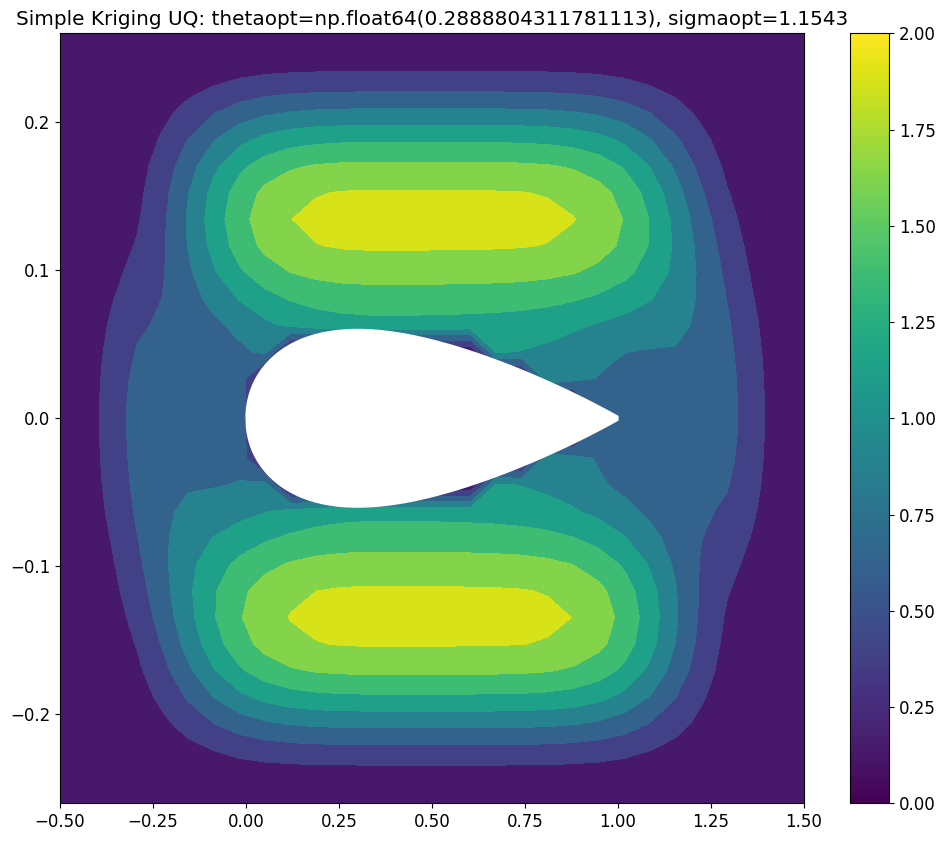

In [15]:
## Simple Kriging uncertainty in prediction.
## Generalized chi^2 distribtion. Quadratic form of two dependent gaussian vectors vx, vy. 
if UQFLAG == 1:
    CondVar = sigmaopt**2 * CondVar;
    CVxVx = np.diag(CondVar[:qout, :qout])                        # Var[Vx]
    CVxVy = np.diag(CondVar[:qout, qout:])                        # Cov[Vx, Vy]
    CVyVy = np.diag(CondVar[qout:, qout:])                        # Var[Vy]
    ChiVar = np.zeros(qout)                                       # Chi^2 params.
    for i in range(qout):
        Mu = np.array([vxhat[i],                                  # predicted Vx 
                       vyhat[i]])                                 # predicted Vy
        Cov = np.array([[CVxVx[i], CVxVy[i]],                     # Cov matrix for point prediction
                        [CVxVy[i], CVyVy[i]]])
        eigvect, eigmatrix = np.linalg.eigh(Cov)
        b = eigmatrix @ Mu
        ChiVar[i] = np.sum(2 * eigvect**2 * (1 + 2*b**2))         # A derivation can be found in https://math.stackexchange.com/a/442916
                                                                  # A paper about normal ---> generalized chi^2: https://arxiv.org/pdf/2012.14331
    plt.figure(figsize = (12,10))
    plt.cla()
    UQ = np.zeros(XX.shape[0])                                    # initializing the uncertainty array.
    UQ[~withinairfoil] = ChiVar                                   # Assigning the computed uncertainty to points outside the airfoil.
    plt.contourf(XX.reshape(30, 30), YY.reshape(30,30), 
                 2*np.sqrt(UQ).reshape(30, 30),)
                #  vmin = 0.0, vmax = 1.0)                        # Same scale colorbar
    cnorm = Normalize(vmin = 0.0, vmax = 2.0)                     # To normalize the true values and scaling them to 0.0 --> 0.2 for the colorbar
    plt.colorbar(cm.ScalarMappable(norm=cnorm), ax = plt.gca())
    # plt.clim(0.0, 0.01)     
    # plt.colorbar()
    # plt.clim(0.0, 0.200)                                        # Same scale colorbar
    plt.fill(XB, YB,                                              
            alpha = 1, c = 'white', label='Obstacle')
    plt.title(f'Simple Kriging UQ: {thetaopt=}, {sigmaopt=:.4f}')
    # if figsave == 1:
    #     plt.savefig(IMGPATH+'FluidCKUQ.pdf', dpi = 300, bbox_inches = 'tight', pad_inches = 0)
    plt.show()